## data stock states and forecast behavior
We will reuse Project 1's data stock data. Each row represents one stock on one trading day. The same stock might, for example, shift between a calm state and a more volatile one. This preserves the connection to short-term forecasting.

**Main question**: What recurring data stock states does GMM identify, how stable are they, and do Project 1's forecast errors vary across states?

We will use Gaussian Mixture Models (GMM) as the primary method and Ward/agglomerative clustering for comparison. GMM gives component assignments and probabilities for new data observations. Ward shows a hierarchy but does not have built-in predict method for new rows in scikit-learn.

We use data to and including 2020. Target will not be loaded in the clustering analysis. We read project 1's Parquet features directly. Price and finance features will not be recalculated and will be reused from project 1's cleaned data. Company name and sector are used only as metadata.

Model selection uses expanding-window validation in 2018, 2019 and 2020. After choosing the features and hyperparameters, the final pipeline is refitted on 2017-2020 before the 2021 evaluation.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "src/config.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src/config.py").exists():
    raise FileNotFoundError("Could not find 'src/config.py' in the current or parent directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0,str(ROOT))
    
    
from src.config import ProjectConfig
from src.io_utils import prepare_run, read_json, write_json, record_input_checksums, save_figure, sha256, ensure_unlocked
from src.data import CORE, load_daily_until, load_stock_metadata

cfg = ProjectConfig()
OUT = prepare_run(root=ROOT, cfg=cfg)
ensure_unlocked(OUT)
sns.set_theme(style="whitegrid")

print(
    f"Project root: {ROOT}\n"
    f"Output directory: {OUT}\n"
    f"Config: {cfg}"
)

Project root: C:\Users\MY NGOC\Documents\MAU_TACAS_68803\DA631E_ArtificialIntelligenceForDataScience\Project_2_UnsupervisedLearning
Output directory: C:\Users\MY NGOC\Documents\MAU_TACAS_68803\DA631E_ArtificialIntelligenceForDataScience\Project_2_UnsupervisedLearning\output\walk_forward_01
Config: ProjectConfig(random_seed=42, run_profile='full', run_name='walk_forward_01', development_start='2017-01-01', feature_selection_end='2017-12-31', development_end='2020-12-31', test_start='2021-01-01', test_end='2021-12-31', stock_list_path='../Project_1_SupervisedLearning/data/train/stock_list.csv', project1_features_path='../Project_1_SupervisedLearning/data/processed/features_table.parquet', project1_feature_audit_path='../Project_1_SupervisedLearning/reports/features_audit.json', development_features_path='data/processed/development_features.parquet', development_audit_path='data/processed/development_audit.json', pred_path=None, pred_column='Prediction', min_history_days=60, max_feature_m

In [2]:
record_input_checksums(ROOT, cfg, OUT)

data, audit = load_daily_until(root=ROOT, cfg=cfg, end=cfg.development_end)
assert "Target" not in data and "Prediction" not in data, "Data should not contain 'Target' or 'Prediction' columns at this stage."
assert data.index.is_unique
assert data["Date"].max() < pd.Timestamp(cfg.test_start)
display(pd.Series(audit).drop('allowed_features'))
display(data.head())

rows_before_filter             1880531
rows_after_filter              1754860
stocks                            1990
dates                              915
min_date                    2017-03-31
max_date                    2020-12-30
input_features_available            46
dtype: object

,Date,SecuritiesCode,Close,Volume,OpenToCloseReturn,HighLowRange,GapReturn,LogReturn1Day,Momentum5Days,Momentum20Days,Momentum60Days,Volatility20Days,Volatility60Days,VolatilityRatio20To60,CloseToMovingAverage20Days,LogVolume,VolumeVs20Days,LogTurnover,ExpectedDividend,DaysSinceLastTrade,NoTradeFlag,MarketWideNoTradeFlag,StockSpecificNoTradeFlag,HasExpectedDividend,SupervisionFlag,AdjustmentEventFlag,Return1DayRankPct,Momentum20DaysRankPct,Volatility20DaysRankPct,FinancialAgeDays,Fin_OperatingMargin,Fin_OrdinaryMargin,Fin_ProfitMargin,Fin_ReturnOnAssets,Fin_NetSales_SignedLog,Fin_OperatingProfit_SignedLog,Fin_OrdinaryProfit_SignedLog,Fin_Profit_SignedLog,Fin_EarningsPerShare_SignedLog,Fin_TotalAssets_SignedLog,Fin_Equity_SignedLog,Fin_EquityToAssetRatio_SignedLog,Fin_BookValuePerShare_SignedLog,Fin_ResultDividendPerShareAnnual_SignedLog,Fin_ForecastDividendPerShareAnnual_SignedLog,Fin_ForecastNetSales_SignedLog,Fin_ForecastOperatingProfit_SignedLog,Fin_ForecastOrdinaryProfit_SignedLog,Fin_ForecastProfit_SignedLog,Fin_ForecastEarningsPerShare_SignedLog,FinancialAvailableDate,DayNumber,HistoryCount
RowKey,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2017-03-31|1301,2017-03-31,1301,2936.0,62300,-0.004071,0.020436,0.002039,-0.002042,-0.060480,-0.027815,0.070751,0.013283,0.009067,1.465015,-0.056677,11.039733,-0.299369,19.024520,0.0,0.0,0,0,0,0,0,0,0.743070,0.471880,0.513123,42.0,0.015958,0.015708,0.013607,0.220017,25.916084,21.778274,21.762482,21.618946,5.456432,25.486875,23.972826,0.196389,NaN,NaN,4.110874,26.220434,21.976029,21.917188,21.465203,5.303006,2017-02-18,60.0,60
2017-03-31|1332,2017-03-31,1332,555.0,2842400,-0.024605,0.027027,0.005300,-0.019626,-0.036458,-0.021164,-0.028021,0.013811,0.018886,0.731256,-0.018134,14.860160,0.065770,21.179127,0.0,0.0,0,0,0,0,0,0,0.205757,0.532405,0.558650,38.0,0.039917,0.044196,0.026400,0.291469,26.873487,23.652538,23.754365,23.239106,3.773680,26.843576,25.610754,0.222343,5.842384,1.791759,1.945910,27.165806,23.791319,23.880266,23.362323,3.877224,2017-02-22,60.0,60
2017-03-31|1333,2017-03-31,1333,3370.0,234000,-0.018923,0.023739,0.000000,-0.019104,-0.038516,-0.008824,0.049844,0.013011,0.013727,0.947820,-0.032999,12.363081,-0.008535,20.485744,0.0,0.0,0,0,0,0,0,0,0.217484,0.628281,0.485806,53.0,0.037718,0.038980,0.024684,0.217493,27.238540,23.960924,23.993823,23.536937,5.761202,26.998896,25.473307,0.165514,NaN,NaN,3.433987,27.491759,23.981362,24.019103,23.362323,5.587136,2017-02-07,60.0,60
2017-03-31|1376,2017-03-31,1376,1463.0,6600,-0.020094,0.023240,0.000000,-0.020298,0.006190,-0.005438,-0.056129,0.009300,0.009468,0.982234,-0.002114,8.794976,0.036333,16.083069,0.0,0.0,0,0,0,0,0,0,0.191365,0.650777,0.136047,84.0,0.013180,0.014686,0.009916,0.494439,23.897144,19.568083,19.676297,19.283571,3.055886,24.225183,23.520852,0.401457,7.242948,NaN,3.258097,24.785432,21.441106,21.511723,21.108528,4.837868,2017-01-07,60.0,60
2017-03-31|1377,2017-03-31,1377,3485.0,137100,-0.022440,0.022956,0.002813,-0.019887,0.001437,0.077280,0.046547,0.011263,0.013840,0.813752,0.030303,11.828473,0.126749,19.984689,0.0,0.0,0,0,0,0,0,0,0.201493,0.925013,0.313337,74.0,0.198434,0.208178,0.153042,0.824773,24.063332,22.446032,22.493972,22.186290,4.574505,25.410799,25.218152,0.600483,NaN,NaN,3.178054,24.807560,22.669176,22.724746,22.371924,4.758320,2017-01-17,60.0,60


In [3]:
before = audit["rows_before_filter"]
after = audit["rows_after_filter"]
removed = before - after

print(f"Removed rows: {removed:,} av {before:,} ({removed / before:.1%})")

Removed rows: 125,671 av 1,880,531 (6.7%)


## Review what were filtered
We remove rows without positive price or positive volume, and rows with NoTradeFlag. We require at least 60 earlier observations and available history for central momentum and risk measures. It makes the result more reusable, but exclude for example early days for new publicly traded. They repeating missing values are filled later by median from respective training fold.

Project 1's features include for example OpenToCloseReturn, rolling volatility, momentum and also financial measures connecting to available days. We control that such dates do not lie after the row's date. 

In [4]:
summary = data.groupby(data.Date.dt.year).agg(n_rows=('SecuritiesCode','size')
                                            ,n_stocks =('SecuritiesCode','nunique')
                                            ,n_dates =('Date','nunique')
                                            )

display(summary)

,n_rows,n_stocks,n_dates
Date,,,
2017,349699,1884,187
2018,464576,1920,245
2019,465067,1949,241
2020,475518,1990,242


In [5]:
# Missingness is measured before imputation, using all loaded data (2017-2020).
missing_fraction = (
    data[audit["allowed_features"]].isna().mean().sort_values(ascending=False)
)
display(missing_fraction.rename("missing_fraction").to_frame().head(15))

,missing_fraction
Fin_ForecastOperatingProfit_SignedLog,0.056301
Fin_ResultDividendPerShareAnnual_SignedLog,0.044811
Fin_BookValuePerShare_SignedLog,0.039454
Fin_ForecastNetSales_SignedLog,0.030904
Fin_OperatingMargin,0.030023
Fin_OperatingProfit_SignedLog,0.029746
Fin_ForecastDividendPerShareAnnual_SignedLog,0.027893
Fin_ForecastOrdinaryProfit_SignedLog,0.024250
Fin_ForecastEarningsPerShare_SignedLog,0.021411
Fin_ForecastProfit_SignedLog,0.015671


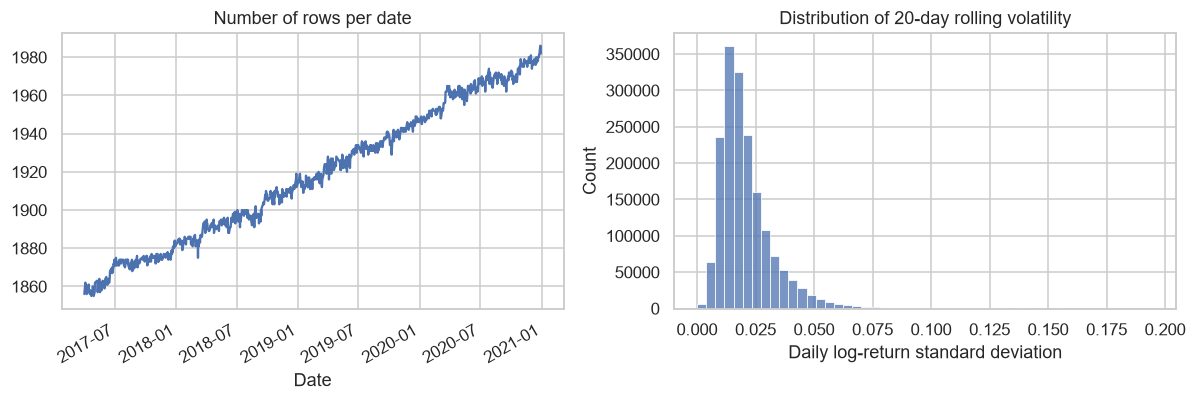

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
data.groupby("Date").size().plot(ax=axes[0], title="Number of rows per date")
sns.histplot(data["Volatility20Days"], bins=50, ax=axes[1])
axes[1].set_title("Distribution of 20-day rolling volatility")
axes[1].set_xlabel("Daily log-return standard deviation")
save_figure(fig, OUT, "01_data_quality.png")
plt.show()

In [7]:
data["Volatility20Days"].describe()

Out[0]: 
count    1.754860e+06
mean     2.081958e-02
std      1.143356e-02
min      0.000000e+00
25%      1.318927e-02
50%      1.801441e-02
75%      2.526304e-02
max      1.950843e-01
Name: Volatility20Days, dtype: float64


The figure on the left shows gradually increasing stock coverage and strongly skewed volatility. Possible explanations include newly listed stocks, stocks accumulating sufficient history, and changing data availability.

The right plot shows mostly moderate volatility with a small high-volatility tail. Most observation appear around 0.01-0.03. A value of 0.02 means approximately 2% daily log-return standard deviation, estimated over the rolling window. 

## Feature diagnostics

All diagnostics use **`data`: all eligible observations loaded through 2020**, including the 2020 validation period. Histograms, extreme-return inspection, missingness and correlations describe this full dataset. No rows are sampled, no values are imputed or scaled, and no outliers are removed.

The loader has already applied trading and history filters. The full development dataset is saved as Parquet in `data/processed/` for the 2018, 2019 and 2020 validation folds. Any learned preprocessing must still be fitted on training rows only. The 2021 test period and Target remain excluded.

### Core feature distributions

Inspect the full ranges for skewness, spikes, nearly constant values and implausible extremes. Volatility is the standard deviation of daily log returns estimated over its rolling window; 0.02 is approximately 2% daily volatility.

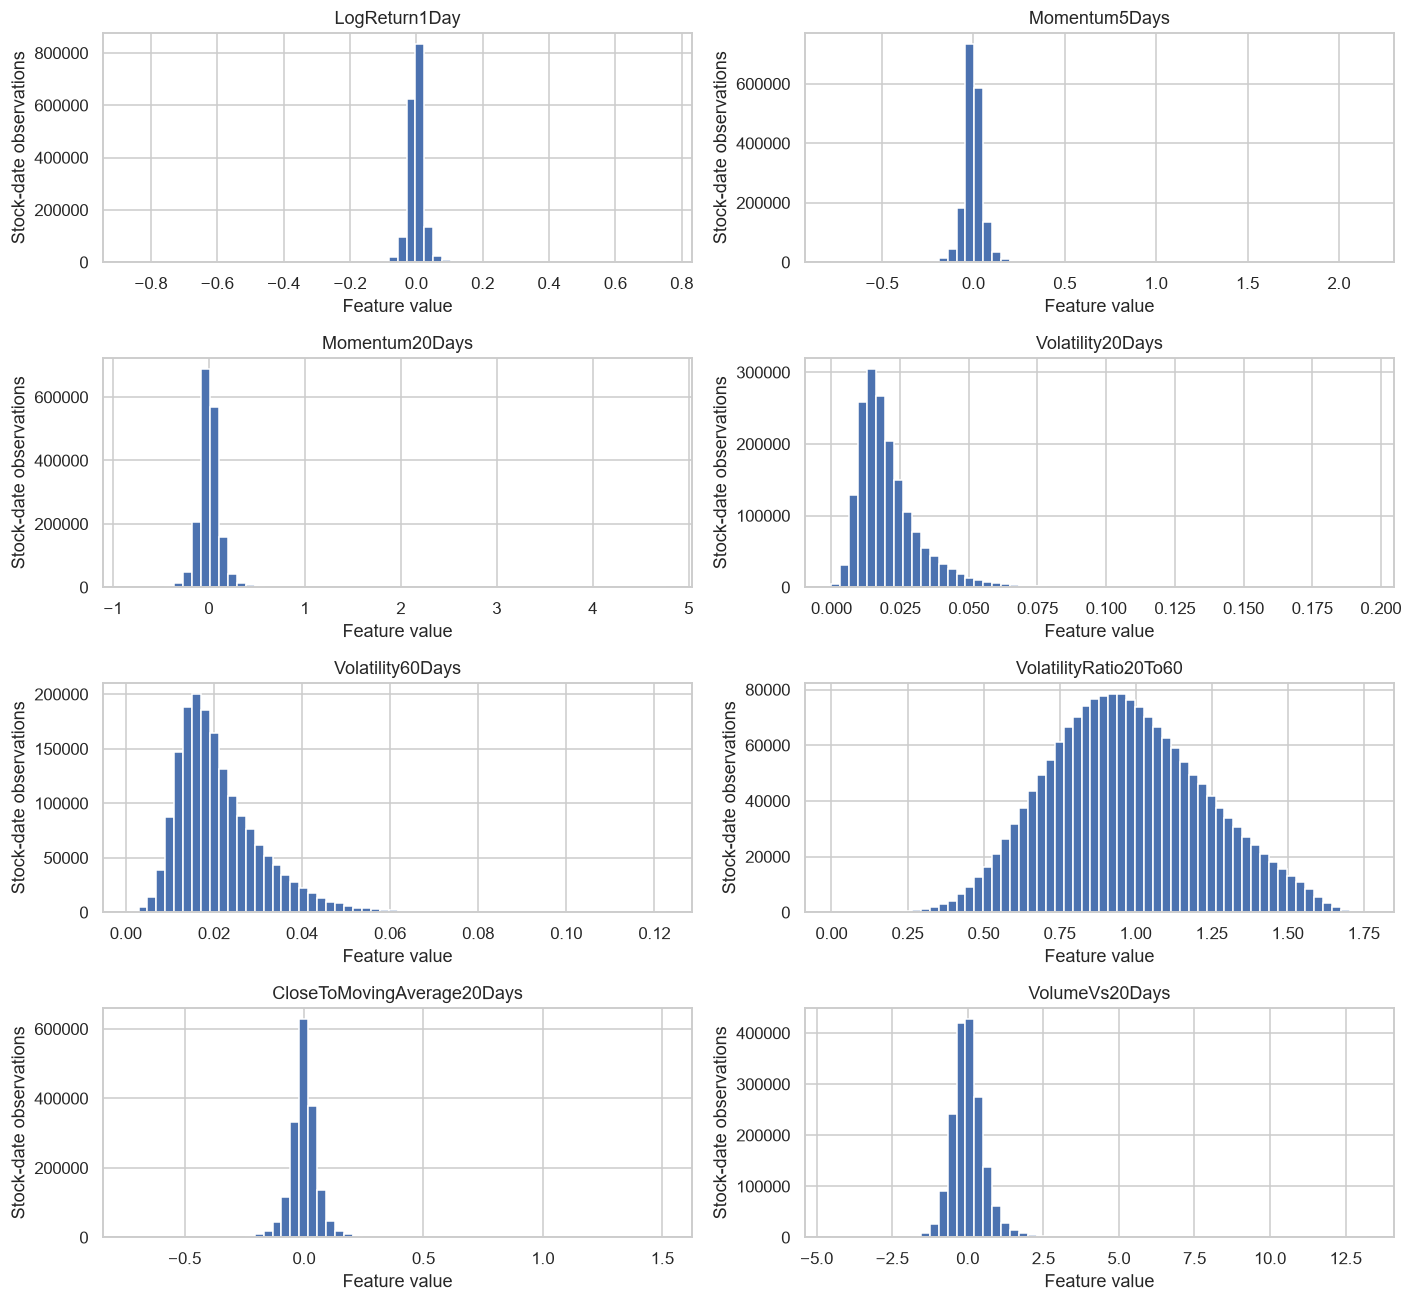

,count,mean,std,min,1%,50%,99%,max
LogReturn1Day,1754860.0,0.000121,0.023800,-0.864034,-0.065187,0.000000,0.068888,0.751186
Momentum5Days,1754860.0,0.002014,0.054648,-0.776260,-0.143253,0.000756,0.166667,2.155702
Momentum20Days,1754860.0,0.007947,0.110712,-0.825298,-0.268728,0.003891,0.338431,4.758621
Volatility20Days,1754860.0,0.020820,0.011434,0.000000,0.005315,0.018014,0.060715,0.195084
Volatility60Days,1754860.0,0.021497,0.009945,0.000875,0.006634,0.019231,0.054289,0.122534
VolatilityRatio20To60,1754860.0,0.973374,0.256876,0.000000,0.437938,0.959353,1.566456,1.762176
CloseToMovingAverage20Days,1754860.0,0.001833,0.059648,-0.729827,-0.165997,0.001757,0.170619,1.513385
VolumeVs20Days,1754860.0,0.022259,0.558181,-4.506806,-1.187517,-0.020788,1.733118,13.219074


In [8]:
fig, axes = plt.subplots(4, 2, figsize=(13, 12))
for feature, ax in zip(CORE, axes.flat):
    ax.hist(data[feature].dropna(), bins=60)
    ax.set(title=feature, xlabel="Feature value", ylabel="Stock-date observations")
save_figure(fig, OUT, "02_core_feature_distributions.png")
plt.show()

display(data[CORE].describe(percentiles=[0.01, 0.5, 0.99]).T)

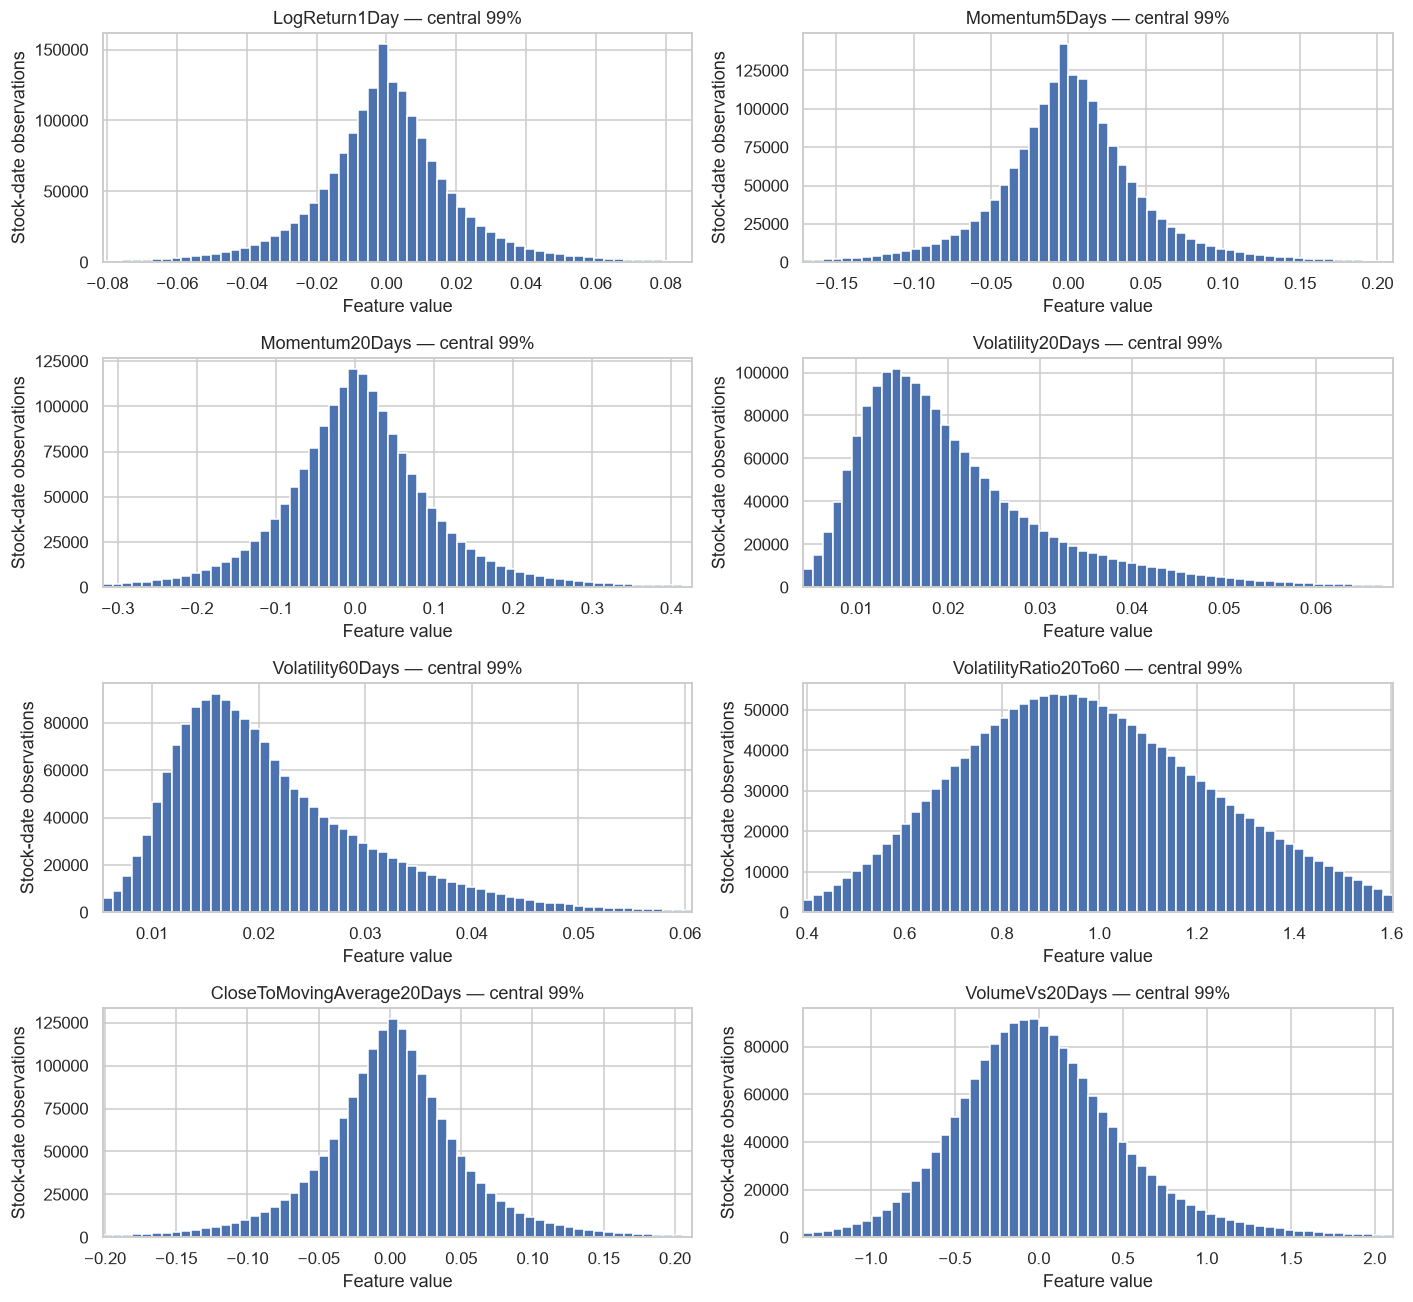

In [9]:
fig, axes = plt.subplots(4, 2, figsize=(13, 12))

for feature, ax in zip(CORE, axes.flat):
    values = data[feature].dropna()
    low, high = values.quantile([0.005, 0.995])

    ax.hist(values, bins=60, range=(low, high))
    ax.set(
        title=f"{feature} — central 99%",
        xlabel="Feature value",
        ylabel="Stock-date observations",
        xlim=(low, high),
    )

save_figure(fig, OUT, "02_core_feature_distributions_zoom.png")
plt.show()

### Largest absolute daily log returns

Inspect these stock/date observations against nearby raw prices and adjustment factors in Project 1. Large returns are investigation candidates, not automatic errors.

In [10]:
largest_return_indices = data["LogReturn1Day"].abs().nlargest(15).index
largest_returns = data.loc[largest_return_indices, [
    "Date", "SecuritiesCode", "Close", "Volume", "LogReturn1Day", "Volatility20Days"
]]
display(largest_returns)
largest_returns.to_csv(OUT / "tables" / "largest_absolute_returns.csv", index=False)

,Date,SecuritiesCode,Close,Volume,LogReturn1Day,Volatility20Days
RowKey,,,,,,
2020-02-27|2157,2020-02-27,2157,601.0,2356800,-0.864034,0.192180
2017-12-18|3540,2017-12-18,3540,4345.0,1559200,0.751186,0.172334
2017-06-26|4772,2017-06-26,4772,65.0,65385000,0.460815,0.107747
2017-07-12|9233,2017-07-12,9233,1643.0,1097700,0.454423,0.115834
2019-02-04|4592,2019-02-04,4592,3710.0,50800,-0.431187,0.138684
2019-06-28|4572,2019-06-28,4572,2462.0,466600,0.392952,0.111241
2018-06-01|9424,2018-06-01,9424,169.0,146085900,0.350775,0.079678
2018-09-06|1435,2018-09-06,1435,533.0,65787200,-0.349520,0.113578
2019-02-05|4592,2019-02-05,4592,2620.0,53568200,-0.347858,0.153749


### Missing values before imputation

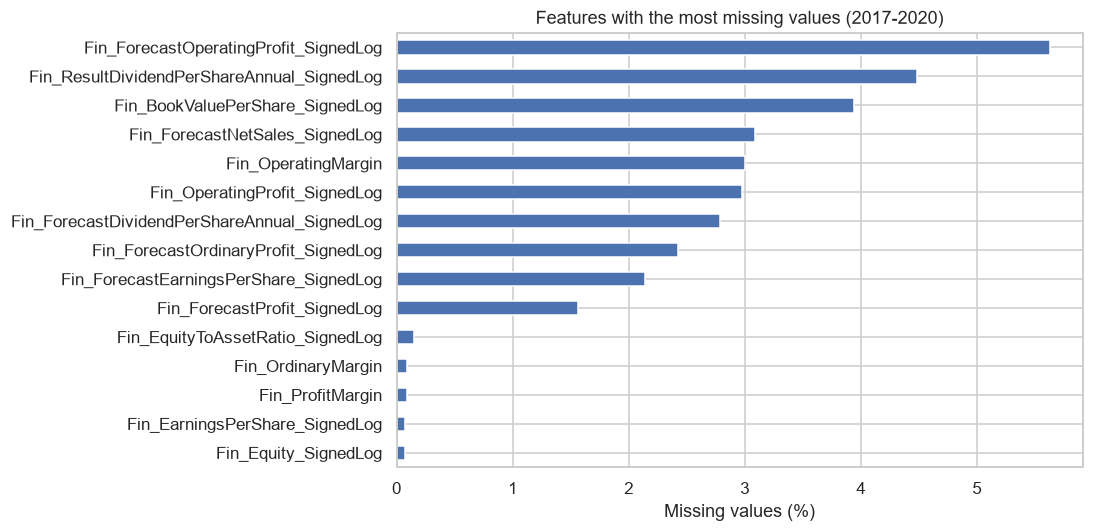

In [11]:
missing_fraction.to_csv(OUT / "tables" / "feature_missingness.csv",
                        header=["missing_fraction"])
fig, ax = plt.subplots(figsize=(10, 5))
missing_fraction.head(15).sort_values().mul(100).plot.barh(ax=ax)
ax.set(xlabel="Missing values (%)", ylabel="",
       title="Features with the most missing values (2017-2020)")
save_figure(fig, OUT, "05_feature_missingness.png")
plt.show()

### Core feature relationships

Spearman correlation measures monotonic relationships using ranks. This heatmap uses all loaded data (2017-2020) and excludes Target, identifiers and metadata.

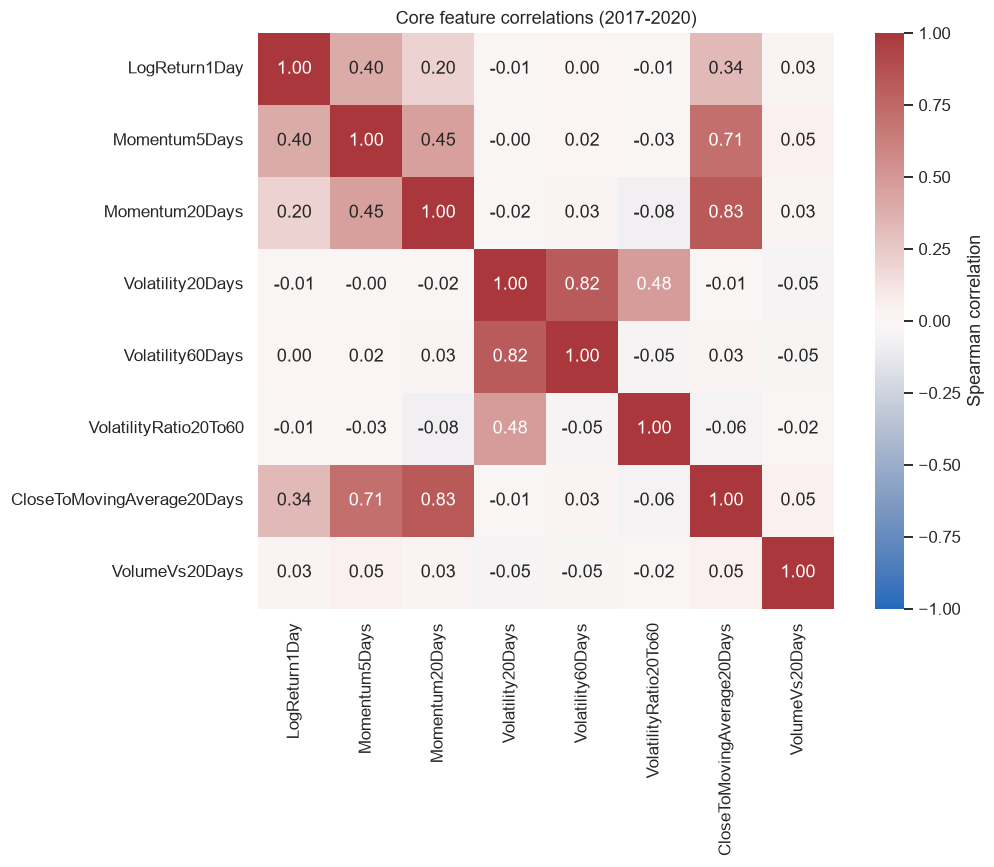

In [12]:
correlations = data[CORE].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"label": "Spearman correlation"})
ax.set_title("Core feature correlations (2017-2020)")
save_figure(fig, OUT, "06_core_feature_correlations.png")
plt.show()

## Showing one stock first and last 5 rows

In [13]:
stock_code = data["SecuritiesCode"].iloc[0]
stock = data.loc[data["SecuritiesCode"].eq(stock_code)].sort_values("Date")
print(f"Stock code: {stock_code}, number of rows: {len(stock):,}")
print(f"Number of columns: {len(stock.columns)}")
display(stock.head(5))
display(stock.tail(5))

Stock code: 1301, number of rows: 915
Number of columns: 53


,Date,SecuritiesCode,Close,Volume,OpenToCloseReturn,HighLowRange,GapReturn,LogReturn1Day,Momentum5Days,Momentum20Days,Momentum60Days,Volatility20Days,Volatility60Days,VolatilityRatio20To60,CloseToMovingAverage20Days,LogVolume,VolumeVs20Days,LogTurnover,ExpectedDividend,DaysSinceLastTrade,NoTradeFlag,MarketWideNoTradeFlag,StockSpecificNoTradeFlag,HasExpectedDividend,SupervisionFlag,AdjustmentEventFlag,Return1DayRankPct,Momentum20DaysRankPct,Volatility20DaysRankPct,FinancialAgeDays,Fin_OperatingMargin,Fin_OrdinaryMargin,Fin_ProfitMargin,Fin_ReturnOnAssets,Fin_NetSales_SignedLog,Fin_OperatingProfit_SignedLog,Fin_OrdinaryProfit_SignedLog,Fin_Profit_SignedLog,Fin_EarningsPerShare_SignedLog,Fin_TotalAssets_SignedLog,Fin_Equity_SignedLog,Fin_EquityToAssetRatio_SignedLog,Fin_BookValuePerShare_SignedLog,Fin_ResultDividendPerShareAnnual_SignedLog,Fin_ForecastDividendPerShareAnnual_SignedLog,Fin_ForecastNetSales_SignedLog,Fin_ForecastOperatingProfit_SignedLog,Fin_ForecastOrdinaryProfit_SignedLog,Fin_ForecastProfit_SignedLog,Fin_ForecastEarningsPerShare_SignedLog,FinancialAvailableDate,DayNumber,HistoryCount
RowKey,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2017-03-31|1301,2017-03-31,1301,2936.0,62300,-0.004071,0.020436,0.002039,-0.002042,-6.048000e-02,-0.027815,0.070751,0.013283,0.009067,1.465015,-0.056677,11.039733,-0.299369,19.024520,0.0,0.0,0,0,0,0,0,0,0.743070,0.471880,0.513123,42.0,0.015958,0.015708,0.013607,0.220017,25.916084,21.778274,21.762482,21.618946,5.456432,25.486875,23.972826,0.196389,NaN,NaN,4.110874,26.220434,21.976029,21.917188,21.465203,5.303006,2017-02-18,60.0,60
2017-04-03|1301,2017-04-03,1301,3010.0,80800,0.021724,0.028212,0.003406,0.024892,-3.525641e-02,-0.009868,0.099343,0.014443,0.009563,1.510205,-0.032434,11.299745,-0.068401,19.309428,0.0,0.0,0,0,0,0,0,0,0.933937,0.574719,0.588109,45.0,0.015958,0.015708,0.013607,0.220017,25.916084,21.778274,21.762482,21.618946,5.456432,25.486875,23.972826,0.196389,NaN,NaN,4.110874,26.220434,21.976029,21.917188,21.465203,5.303006,2017-02-18,61.0,61
2017-04-04|1301,2017-04-04,1301,3010.0,77200,0.001664,0.012404,-0.001661,0.000000,-3.370787e-02,-0.032154,0.098540,0.013370,0.009565,1.397830,-0.030877,11.254168,-0.093061,19.263850,0.0,0.0,0,0,0,0,0,0,0.831113,0.477772,0.475094,46.0,0.015958,0.015708,0.013607,0.220017,25.916084,21.778274,21.762482,21.618946,5.456432,25.486875,23.972826,0.196389,NaN,NaN,4.110874,26.220434,21.976029,21.917188,21.465203,5.303006,2017-02-18,62.0,62
2017-04-05|1301,2017-04-05,1301,3005.0,35800,-0.003317,0.012024,0.001661,-0.001663,-1.661130e-03,-0.035313,0.093523,0.013348,0.009572,1.394492,-0.030770,10.485731,-0.822114,18.493736,0.0,0.0,0,0,0,0,0,0,0.510922,0.470809,0.468666,47.0,0.015958,0.015708,0.013607,0.220017,25.916084,21.778274,21.762482,21.618946,5.456432,25.486875,23.972826,0.196389,NaN,NaN,4.110874,26.220434,21.976029,21.917188,21.465203,5.303006,2017-02-18,63.0,63
2017-04-06|1301,2017-04-06,1301,2942.0,34600,-0.012752,0.018021,-0.008319,-0.021188,1.040834e-17,-0.061563,0.071767,0.013872,0.010006,1.386374,-0.048127,10.451638,-0.815694,18.438454,0.0,0.0,0,0,0,0,0,0,0.474161,0.420996,0.454740,48.0,0.015958,0.015708,0.013607,0.220017,25.916084,21.778274,21.762482,21.618946,5.456432,25.486875,23.972826,0.196389,NaN,NaN,4.110874,26.220434,21.976029,21.917188,21.465203,5.303006,2017-02-18,64.0,64


,Date,SecuritiesCode,Close,Volume,OpenToCloseReturn,HighLowRange,GapReturn,LogReturn1Day,Momentum5Days,Momentum20Days,Momentum60Days,Volatility20Days,Volatility60Days,VolatilityRatio20To60,CloseToMovingAverage20Days,LogVolume,VolumeVs20Days,LogTurnover,ExpectedDividend,DaysSinceLastTrade,NoTradeFlag,MarketWideNoTradeFlag,StockSpecificNoTradeFlag,HasExpectedDividend,SupervisionFlag,AdjustmentEventFlag,Return1DayRankPct,Momentum20DaysRankPct,Volatility20DaysRankPct,FinancialAgeDays,Fin_OperatingMargin,Fin_OrdinaryMargin,Fin_ProfitMargin,Fin_ReturnOnAssets,Fin_NetSales_SignedLog,Fin_OperatingProfit_SignedLog,Fin_OrdinaryProfit_SignedLog,Fin_Profit_SignedLog,Fin_EarningsPerShare_SignedLog,Fin_TotalAssets_SignedLog,Fin_Equity_SignedLog,Fin_EquityToAssetRatio_SignedLog,Fin_BookValuePerShare_SignedLog,Fin_ResultDividendPerShareAnnual_SignedLog,Fin_ForecastDividendPerShareAnnual_SignedLog,Fin_ForecastNetSales_SignedLog,Fin_ForecastOperatingProfit_SignedLog,Fin_ForecastOrdinaryProfit_SignedLog,Fin_ForecastProfit_SignedLog,Fin_ForecastEarningsPerShare_SignedLog,FinancialAvailableDate,DayNumber,HistoryCount
RowKey,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2020-12-24|1301,2020-12-24,1301,2917.0,13900,0.001373,0.009625,0.000000,0.001372,-0.001027,0.038448,0.024947,0.007066,0.010875,0.649727,0.021359,9.539716,-0.002703,17.517955,0.0,0.0,0,0,0,0,0,0,0.337169,0.748870,0.021095,48.0,0.0118,0.012879,0.013495,0.298244,25.484251,21.044624,21.132059,21.17879,4.995725,25.473488,24.263645,0.264669,8.021998,4.26268,4.26268,26.321688,22.15835,22.227343,21.821878,5.635932,2020-11-07,970.0,971
2020-12-25|1301,2020-12-25,1301,2916.0,8300,0.004478,0.009301,-0.004799,-0.000343,-0.007150,0.034409,0.042173,0.007071,0.010633,0.665037,0.019277,9.024131,-0.469552,17.001979,0.0,0.0,0,0,0,0,0,0,0.341000,0.734304,0.023104,49.0,0.0118,0.012879,0.013495,0.298244,25.484251,21.044624,21.132059,21.17879,4.995725,25.473488,24.263645,0.264669,8.021998,4.26268,4.26268,26.321688,22.15835,22.227343,21.821878,5.635932,2020-11-07,971.0,972
2020-12-28|1301,2020-12-28,1301,2950.0,22900,0.007170,0.013746,0.004458,0.011592,0.001018,0.055456,0.054325,0.006969,0.010725,0.649830,0.028376,10.038936,0.535654,18.028453,0.0,0.0,0,0,0,0,0,0,0.863500,0.738825,0.031642,52.0,0.0118,0.012879,0.013495,0.298244,25.484251,21.044624,21.132059,21.17879,4.995725,25.473488,24.263645,0.264669,8.021998,4.26268,4.26268,26.321688,22.15835,22.227343,21.821878,5.635932,2020-11-07,972.0,973
2020-12-29|1301,2020-12-29,1301,2961.0,15100,0.004410,0.006112,-0.000678,0.003722,0.016478,0.062433,0.081051,0.006847,0.010326,0.663068,0.029090,9.622516,0.127739,17.615732,0.0,0.0,0,0,0,0,0,0,0.226000,0.766951,0.024611,53.0,0.0118,0.012879,0.013495,0.298244,25.484251,21.044624,21.132059,21.17879,4.995725,25.473488,24.263645,0.264669,8.021998,4.26268,4.26268,26.321688,22.15835,22.227343,21.821878,5.635932,2020-11-07,973.0,974
2020-12-30|1301,2020-12-30,1301,2951.0,11100,0.001357,0.012658,-0.004728,-0.003383,0.013045,0.049804,0.046825,0.006859,0.009691,0.707845,0.023125,9.314790,-0.138012,17.304600,0.0,0.0,0,0,0,0,0,0,0.597000,0.766449,0.023104,54.0,0.0118,0.012879,0.013495,0.298244,25.484251,21.044624,21.132059,21.17879,4.995725,25.473488,24.263645,0.264669,8.021998,4.26268,4.26268,26.321688,22.15835,22.227343,21.821878,5.635932,2020-11-07,974.0,975


In [14]:
development_path = ROOT / cfg.development_features_path
development_path.parent.mkdir(parents=True, exist_ok=True)
data.to_parquet(development_path, index=True)

audit["preparation_config"] = {name: getattr(cfg, name) for name in (
    "development_start", "development_end", "min_history_days"
)}
audit["source_checksums"] = read_json(OUT / "source_checksums.json")
audit["dataset_sha256"] = sha256(development_path)
write_json(ROOT / cfg.development_audit_path, audit)
write_json(OUT / "data_audit.json", audit)

metadata = load_stock_metadata(ROOT, cfg)
metadata.to_csv(OUT / "metadata.csv", index=False)
write_json(OUT / "data_schema.json", {
    "columns": data.columns.tolist(), "n_development_rows": len(data),
    "development_start": cfg.development_start, "development_end": cfg.development_end,
})
print(f"Saved {len(data):,} development rows to {development_path}")

Saved 1,754,860 development rows to C:\Users\MY NGOC\Documents\MAU_TACAS_68803\DA631E_ArtificialIntelligenceForDataScience\Project_2_UnsupervisedLearning\data\processed\development_features.parquet
